In [95]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [96]:
DATA_PATH = r"C:\network-traffic-ai\data\raw\localnet_dynamics.csv" 
# backlashes can introduce speacial escape sequences 
# we use r before the path to treat it as a raw string  
df=pd.read_csv(DATA_PATH)

C:\Users\Sunidhi Chaurasia\AppData\Local\Temp\ipykernel_43776\1098906426.py:4: DtypeWarning: Columns (47) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(DATA_PATH)


In [97]:
print("Dataset loaded successfully")
print("Dataset shape : ", df.shape)

Dataset loaded successfully
Dataset shape :  (54617, 67)


In [98]:
df.head()

,run_id,host_label,sample_index,timestamp_utc,timestamp_local,epoch_s,elapsed_s,link_type,gateway_ip,dns_server,...,sample_duration_s,label_outage,label_packet_loss,label_high_latency,label_high_jitter,label_gateway_degraded,label_anomaly,event_category,event_description,notes
0,desktop-eth_20260920_123407,desktop-eth,0,2026-09-20T16:34:22Z,2026-09-20T12:34:22-04:00,1789922062,0.0,unknown,192.168.1.1,192.168.1.1,...,65.70,0,0,0,0,0,0,NaN,NaN,NaN
1,desktop-eth_20260920_123407,desktop-eth,1,2026-09-20T16:35:52Z,2026-09-20T12:35:52-04:00,1789922152,90.0,unknown,192.168.1.1,192.168.1.1,...,12.41,0,1,0,0,0,1,NaN,NaN,NaN
2,desktop-eth_20260920_123407,desktop-eth,2,2026-09-20T16:36:22Z,2026-09-20T12:36:22-04:00,1789922182,120.0,unknown,192.168.1.1,192.168.1.1,...,10.20,0,0,0,0,0,0,NaN,NaN,NaN
3,desktop-eth_20260920_123407,desktop-eth,3,2026-09-20T16:36:52Z,2026-09-20T12:36:52-04:00,1789922212,150.0,unknown,192.168.1.1,192.168.1.1,...,9.32,0,0,0,0,0,0,NaN,NaN,NaN
4,desktop-eth_20260920_123407,desktop-eth,4,2026-09-20T16:37:22Z,2026-09-20T12:37:22-04:00,1789922242,180.0,unknown,192.168.1.1,192.168.1.1,...,11.07,0,0,1,1,0,1,NaN,NaN,NaN


In [99]:
print("All column name: ")
df.columns

All column name: 


Index(['run_id', 'host_label', 'sample_index', 'timestamp_utc',
       'timestamp_local', 'epoch_s', 'elapsed_s', 'link_type', 'gateway_ip',
       'dns_server', 'target', 'collector_version', 'collector_os',
       'interval_s', 'rtt_resolution_ms', 'date_local', 'hour_local',
       'weekday_local', 'is_weekend', 'gap_before_s', 'rtt_min_ms',
       'rtt_avg_ms', 'rtt_median_ms', 'rtt_max_ms', 'rtt_stddev_ms',
       'jitter_ms', 'packets_sent', 'packets_received', 'packet_loss_pct',
       'gateway_rtt_min_ms', 'gateway_rtt_avg_ms', 'gateway_rtt_max_ms',
       'gateway_jitter_ms', 'gateway_packet_loss_pct', 'tcp_connect_min_ms',
       'tcp_connect_median_ms', 'dns_resolve_ms', 'dns_recursive_ms',
       'http_ms', 'http_status', 'wifi_ssid', 'wifi_signal_pct',
       'wifi_rssi_dbm', 'wifi_rx_mbps', 'wifi_tx_mbps', 'wifi_channel',
       'wifi_band_ghz', 'wifi_phy', 'download_mbps', 'upload_mbps',
       'speedtest_ping_ms', 'download_loaded_latency_ms',
       'upload_loaded_late

In [100]:
print("dataset information:")
df.info()

dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54617 entries, 0 to 54616
Data columns (total 67 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   run_id                      54617 non-null  object 
 1   host_label                  54617 non-null  object 
 2   sample_index                54617 non-null  int64  
 3   timestamp_utc               54617 non-null  object 
 4   timestamp_local             54617 non-null  object 
 5   epoch_s                     54617 non-null  int64  
 6   elapsed_s                   54617 non-null  float64
 7   link_type                   54617 non-null  object 
 8   gateway_ip                  54617 non-null  object 
 9   dns_server                  54617 non-null  object 
 10  target                      54617 non-null  object 
 11  collector_version           54617 non-null  object 
 12  collector_os                54617 non-null  object 
 13  interval_s

In [101]:
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False))
print("Total missing values :", df.isnull().sum().sum())
print("Duplicate rows: " , df.duplicated().sum())


Missing values per column:
upload_loaded_latency_ms    54617
event_description           54617
event_category              54617
wifi_ssid                   54617
lan_retransmits             54617
                            ...  
weekday_local                   0
is_weekend                      0
packets_sent                    0
packets_received                0
gateway_packet_loss_pct         0
Length: 67, dtype: int64
Total missing values : 1090404
Duplicate rows:  0


In [102]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sample_index,54617.0,2.730800e+04,15766.714163,0.000000e+00,1.365400e+04,2.730800e+04,4.096200e+04,5.461600e+04
epoch_s,54617.0,1.790749e+09,477073.766606,1.789922e+09,1.790336e+09,1.790750e+09,1.791163e+09,1.791575e+09
elapsed_s,54617.0,8.272569e+05,477067.702372,0.000000e+00,4.139400e+05,8.274300e+05,1.240440e+06,1.653300e+06
interval_s,54617.0,3.000000e+01,0.000000,3.000000e+01,3.000000e+01,3.000000e+01,3.000000e+01,3.000000e+01
rtt_resolution_ms,54617.0,1.000000e+00,0.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
hour_local,54617.0,1.150526e+01,6.901630,0.000000e+00,6.000000e+00,1.200000e+01,1.700000e+01,2.300000e+01
weekday_local,54617.0,2.793819e+00,1.967498,0.000000e+00,1.000000e+00,3.000000e+00,4.000000e+00,6.000000e+00
is_weekend,54617.0,2.334804e-01,0.423049,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
gap_before_s,54616.0,3.027173e+01,3.272058,1.000000e+01,3.000000e+01,3.000000e+01,3.000000e+01,1.220000e+02
rtt_min_ms,54599.0,1.043208e+01,3.124936,5.000000e+00,1.000000e+01,1.000000e+01,1.000000e+01,2.630000e+02


In [103]:
df["timestamp_utc"].head()

0    2026-09-20T16:34:22Z
1    2026-09-20T16:35:52Z
2    2026-09-20T16:36:22Z
3    2026-09-20T16:36:52Z
4    2026-09-20T16:37:22Z
Name: timestamp_utc, dtype: object

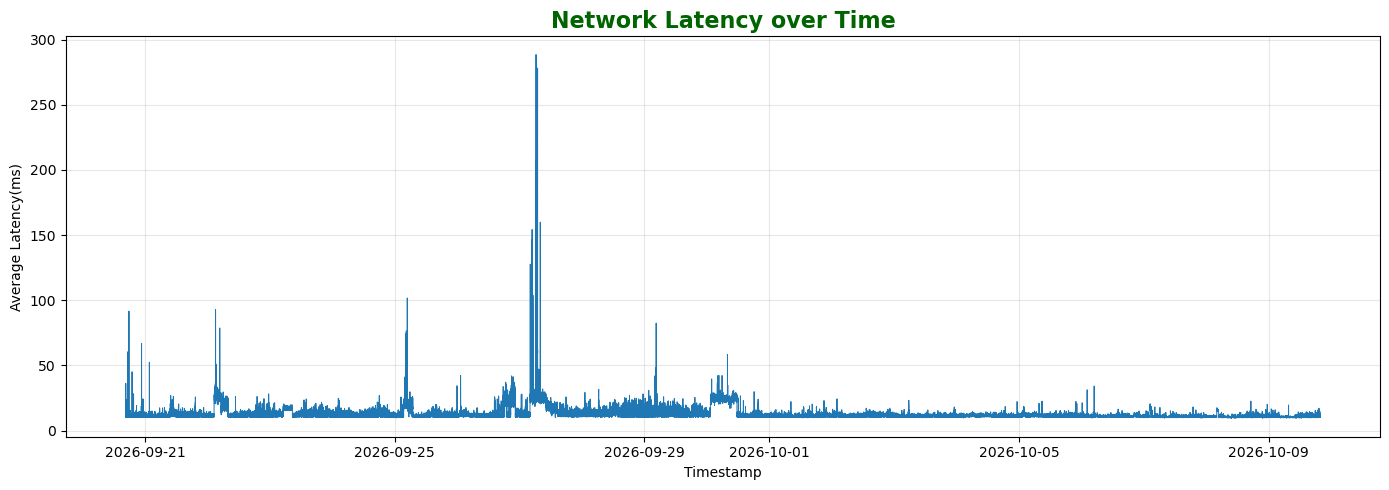

In [104]:
df["timestamp_utc"]= pd.to_datetime(df['timestamp_utc'],errors="coerce",utc=True)
df= df.sort_values("timestamp_utc")
plt.figure(figsize=(14,5))
plt.plot(df["timestamp_utc"],df["rtt_avg_ms"],linewidth=0.7)
plt.title("Network Latency over Time",fontsize=16, color="darkgreen",fontweight='bold')
plt.xlabel("Timestamp")
plt.ylabel("Average Latency(ms)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


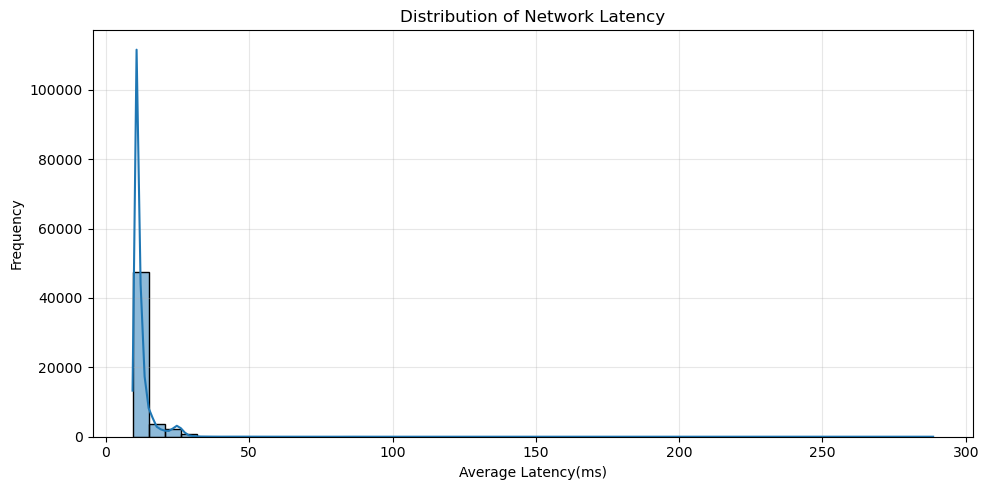

In [105]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='rtt_avg_ms',bins=50,kde=True)
plt.title("Distribution of Network Latency")
plt.xlabel("Average Latency(ms)")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Conclusion : Distribution of Network Latency 
This histogram shows that network latency is positively skewed(right-skewed). Most observations are concentrated at a relatively low latency values, while a small number of observations have much higher value, forming a long tail towards right.These unusually high values may represent latency-spikes or outliers that should be investigated further.
This distribution indicates that network latency is not uniformly distributed. Further analysis is required to understand the causes of these high latency observations before building the prediction model.

In [106]:
print("Latency Statistics :")
df['rtt_avg_ms'].describe()

Latency Statistics :


count    54599.000000
mean        12.580737
std          5.216168
min          9.300000
25%         10.600000
50%         11.100000
75%         12.556000
max        288.600000
Name: rtt_avg_ms, dtype: float64

In [107]:
#Top 10 latency values 
df['rtt_avg_ms'].nlargest(10)

18730    288.600
18801    278.200
18802    266.200
18728    259.500
18800    230.900
18733    207.500
18737    203.700
18729    170.000
18926    160.000
18550    154.333
Name: rtt_avg_ms, dtype: float64

In [108]:
print("Missing values in important columns :")
df[["timestamp_utc","rtt_avg_ms","jitter_ms","packet_loss_pct","tcp_connect_median_ms","http_ms"]].isnull().sum()

Missing values in important columns :


timestamp_utc             0
rtt_avg_ms               18
jitter_ms                18
packet_loss_pct           0
tcp_connect_median_ms    19
http_ms                  52
dtype: int64

In [109]:
# Get the 10 highest latency rows 
top_latency = df.nlargest(10,"rtt_avg_ms")

top_latency[["timestamp_utc","rtt_avg_ms"]].sort_values("timestamp_utc")

,timestamp_utc,rtt_avg_ms
18550,2026-09-27 04:49:59+00:00,154.333
18728,2026-09-27 06:19:29+00:00,259.500
18729,2026-09-27 06:19:59+00:00,170.000
18730,2026-09-27 06:20:29+00:00,288.600
18733,2026-09-27 06:21:59+00:00,207.500
18737,2026-09-27 06:23:59+00:00,203.700
18800,2026-09-27 06:55:29+00:00,230.900
18801,2026-09-27 06:56:01+00:00,278.200
18802,2026-09-27 06:56:29+00:00,266.200
18926,2026-09-27 07:58:29+00:00,160.000


In [110]:
df["tcp_connect_median_ms"].max()

1524.463

In [111]:
top_latency[["timestamp_utc","rtt_avg_ms","jitter_ms","packet_loss_pct","gateway_rtt_avg_ms","tcp_connect_median_ms"]].sort_values("timestamp_utc")

,timestamp_utc,rtt_avg_ms,jitter_ms,packet_loss_pct,gateway_rtt_avg_ms,tcp_connect_median_ms
18550,2026-09-27 04:49:59+00:00,154.333,18.750,10.0,0.2,96.394
18728,2026-09-27 06:19:29+00:00,259.500,31.429,20.0,0.2,260.607
18729,2026-09-27 06:19:59+00:00,170.000,29.889,0.0,0.0,154.474
18730,2026-09-27 06:20:29+00:00,288.600,20.000,0.0,0.2,310.715
18733,2026-09-27 06:21:59+00:00,207.500,25.889,0.0,0.0,179.812
18737,2026-09-27 06:23:59+00:00,203.700,26.111,0.0,0.0,189.394
18800,2026-09-27 06:55:29+00:00,230.900,33.889,0.0,0.0,179.484
18801,2026-09-27 06:56:01+00:00,278.200,39.444,0.0,0.0,298.543
18802,2026-09-27 06:56:29+00:00,266.200,34.000,0.0,0.0,240.823
18926,2026-09-27 07:58:29+00:00,160.000,33.333,0.0,0.0,213.987




### Conclusion: Analysis of High-Latency Observations

The analysis of the top 10 high-latency observations reveals that network latency reaches a maximum of 288.6 ms, which is significantly higher than the typical latency observed in the dataset. These observations are also associated with relatively high jitter and, in some cases, packet loss of up to 20%. The TCP connection establishment time is also high, reaching approximately 310.715 ms, while the measured gateway latency remains very low.

This suggests that the high latency may be associated with delays beyond the local gateway or during connection establishment. However, the exact cause cannot be confirmed from these metrics alone. Since several high-latency observations occur within nearby time intervals, they may represent genuine network performance spikes rather than random outliers. Therefore, these observations should be investigated further and should not be removed without sufficient evidence.

In [112]:
#check the time-gap between consecutive observations
time_diff = df["timestamp_utc"].diff().dt.total_seconds()
print("Most Common Time Intervals in seconds")
time_diff.value_counts().head(10)


Most Common Time Intervals in seconds


timestamp_utc
30.0    50620
32.0     1050
28.0     1042
27.0      408
33.0      405
60.0      345
26.0       98
34.0       97
36.0       46
24.0       46
Name: count, dtype: int64

In [113]:
print("Time Interval Statistics:")
time_diff.describe()

Time Interval Statistics:


count    54616.000000
mean        30.271734
std          3.272058
min         10.000000
25%         30.000000
50%         30.000000
75%         30.000000
max        122.000000
Name: timestamp_utc, dtype: float64

In [114]:
print("Dataset recorded gap information :")
df["gap_before_s"].describe()

Dataset recorded gap information :


count    54616.000000
mean        30.271734
std          3.272058
min         10.000000
25%         30.000000
50%         30.000000
75%         30.000000
max        122.000000
Name: gap_before_s, dtype: float64

In [115]:
print("Total rows :", len(df))
print("Unique Timestamps :", df["timestamp_utc"].nunique())
print("Duplicate Timestamps :", df["timestamp_utc"].duplicated().sum())
print("Missing Timestamps :", df["timestamp_utc"].isna().sum())


Total rows : 54617
Unique Timestamps : 54617
Duplicate Timestamps : 0
Missing Timestamps : 0


In [116]:
df= df.sort_values("timestamp_utc").copy()
latency_by_time= df.set_index("timestamp_utc")["rtt_avg_ms"]
future_timestamp= df["timestamp_utc"] + pd.Timedelta(seconds=30)
df["target_rtt_30s"]= future_timestamp.map(latency_by_time)

print("Total rows :", len(df) )
print("Valid Targets: ", df["target_rtt_30s"].notna().sum())
print("Missing Targets :", df["target_rtt_30s"].isna().sum())
print("Percentage of Missing Targets :",round( df["target_rtt_30s"].isna().mean()*100,2),"%")



Total rows : 54617
Valid Targets:  50608
Missing Targets : 4009
Percentage of Missing Targets : 7.34 %


In [117]:
model_df= df.dropna(subset=["target_rtt_30s"]).copy()
print("Original Rows:",len(df))
print("Rows available for forecasting",len(model_df))
print("Missing target",model_df["target_rtt_30s"].isna().sum())

Original Rows: 54617
Rows available for forecasting 50608
Missing target 0


In [118]:
df[["timestamp_utc","rtt_avg_ms","target_rtt_30s"]].head(15)

,timestamp_utc,rtt_avg_ms,target_rtt_30s
0,2026-09-20 16:34:22+00:00,10.500,NaN
1,2026-09-20 16:35:52+00:00,11.222,10.900
2,2026-09-20 16:36:22+00:00,10.900,10.500
3,2026-09-20 16:36:52+00:00,10.500,36.300
4,2026-09-20 16:37:22+00:00,36.300,10.800
5,2026-09-20 16:37:52+00:00,10.800,12.400
6,2026-09-20 16:38:22+00:00,12.400,11.000
7,2026-09-20 16:38:52+00:00,11.000,11.000
8,2026-09-20 16:39:22+00:00,11.000,12.400
9,2026-09-20 16:39:52+00:00,12.400,10.300


In [119]:
print("Current Latency Missing", df["rtt_avg_ms"].isnull().sum())
print("Future Target Missing",df["target_rtt_30s"].isnull().sum())

Current Latency Missing 18
Future Target Missing 4009


In [120]:
eda_cols=[    "rtt_avg_ms",
    "rtt_median_ms",
    "rtt_max_ms",
    "jitter_ms",
    "packet_loss_pct",
    "gateway_rtt_avg_ms",
    "gateway_jitter_ms",
    "tcp_connect_median_ms",
    "dns_resolve_ms",
    "http_ms",
    "target_rtt_30s"]
# Correlation
correlation= df[eda_cols].corr(numeric_only=True)
correlation

,rtt_avg_ms,rtt_median_ms,rtt_max_ms,jitter_ms,packet_loss_pct,gateway_rtt_avg_ms,gateway_jitter_ms,tcp_connect_median_ms,dns_resolve_ms,http_ms,target_rtt_30s
rtt_avg_ms,1.000000,0.969996,0.839521,0.633363,0.057865,0.197676,0.158212,0.245926,0.029866,0.051820,0.709504
rtt_median_ms,0.969996,1.000000,0.715323,0.491131,0.020051,0.183540,0.140204,0.241418,0.023976,0.035352,0.717288
rtt_max_ms,0.839521,0.715323,1.000000,0.860038,0.107588,0.200135,0.176910,0.192443,0.037472,0.077262,0.544738
jitter_ms,0.633363,0.491131,0.860038,1.000000,0.169792,0.221951,0.198101,0.141606,0.033249,0.090935,0.417127
packet_loss_pct,0.057865,0.020051,0.107588,0.169792,1.000000,-0.002027,-0.003982,0.042916,0.047360,0.129118,0.050755
gateway_rtt_avg_ms,0.197676,0.183540,0.200135,0.221951,-0.002027,1.000000,0.876452,0.056585,0.016301,0.007491,0.140229
gateway_jitter_ms,0.158212,0.140204,0.176910,0.198101,-0.003982,0.876452,1.000000,0.035081,0.012666,0.003786,0.105917
tcp_connect_median_ms,0.245926,0.241418,0.192443,0.141606,0.042916,0.056585,0.035081,1.000000,0.000964,0.067943,0.180813
dns_resolve_ms,0.029866,0.023976,0.037472,0.033249,0.047360,0.016301,0.012666,0.000964,1.000000,0.022569,0.028978
http_ms,0.051820,0.035352,0.077262,0.090935,0.129118,0.007491,0.003786,0.067943,0.022569,1.000000,0.038797


In [121]:
correlation["target_rtt_30s"].drop("target_rtt_30s").sort_values(ascending=False).to_frame(name="correlation_with_future_latency")

,correlation_with_future_latency
rtt_median_ms,0.717288
rtt_avg_ms,0.709504
rtt_max_ms,0.544738
jitter_ms,0.417127
tcp_connect_median_ms,0.180813
gateway_rtt_avg_ms,0.140229
gateway_jitter_ms,0.105917
packet_loss_pct,0.050755
http_ms,0.038797
dns_resolve_ms,0.028978


# Conclusion 

The correlation analysis shows that rtt_median_ms (0.717) and rtt_avg_ms (0.710) have the strongest positive correlation with future network latency (target_rtt_30s). rtt_max_ms (0.545) also shows a positive relationship, while jitter_ms (0.417) has a moderate positive correlation. Other features, such as tcp_connect_median_ms, gateway_rtt_avg_ms, and packet_loss_pct, show relatively weak linear correlations with future latency.

In [122]:
feature_cols = [
    "rtt_avg_ms",
    "rtt_median_ms",
    "rtt_max_ms",
    "jitter_ms",
    "packet_loss_pct",
    "gateway_rtt_avg_ms",
    "gateway_jitter_ms",
    "tcp_connect_median_ms",
    "dns_resolve_ms",
    "http_ms"
]
target_col= "target_rtt_30s"

# Keeping only rows where future target exists 
model_df= df.dropna(subset=[target_col]).copy()

# Sorting Chronologically 
model_df= model_df.sort_values("timestamp_utc").reset_index(drop=True)

#Separating input features and target(y)
X=model_df[feature_cols]
Y= model_df[target_col]



In [123]:
# Train test split - we will not use the module of sklearn for train -test -split as ours is a time-Series data , so we will do manual splitting 
split_index = int(len(model_df) * 0.80)
X_Train =X.iloc[:split_index]
X_Test = X.iloc[split_index:]
y_train = Y.iloc[:split_index]
y_test =Y.iloc[split_index:]

# Conclusion 
The dataset was divided chronologically into 80% training data and 20% testing data . The training set contains earlier observations, while the testing set contains later information .This approach better reflects real-world netwrok -Latency prediction, where a model is trained on past data to predict future performance.

In [124]:
# Training period 
print("Training Period :")
print(model_df["timestamp_utc"].iloc[0],"to",model_df["timestamp_utc"].iloc[len(X_Train)-1])


Training Period :
2026-09-20 16:35:52+00:00 to 2026-10-06 00:08:39+00:00


In [125]:
print("Testing period")
print(model_df["timestamp_utc"].iloc[len(X_Train)],"to",model_df["timestamp_utc"].iloc[-1])

Testing period
2026-10-06 00:09:09+00:00 to 2026-10-09 19:49:13+00:00


In [126]:
# Check missing values in training and testing features 
print("Missing values in X_Train",X_Train.isnull().sum())
X_Train.isnull().sum().sort_values(ascending=False)
print("Missing values in X_Test",X_Test.isnull().sum())
X_Test.isnull().sum().sort_values(ascending=False)
print("Missing values in y_train", y_train.isnull().sum())
print("Missing values in y_test", y_test.isnull().sum())

Missing values in X_Train rtt_avg_ms                2
rtt_median_ms             2
rtt_max_ms                2
jitter_ms                 2
packet_loss_pct           0
gateway_rtt_avg_ms        2
gateway_jitter_ms         2
tcp_connect_median_ms     2
dns_resolve_ms            2
http_ms                  29
dtype: int64
Missing values in X_Test rtt_avg_ms               0
rtt_median_ms            0
rtt_max_ms               0
jitter_ms                0
packet_loss_pct          0
gateway_rtt_avg_ms       0
gateway_jitter_ms        0
tcp_connect_median_ms    1
dns_resolve_ms           1
http_ms                  3
dtype: int64
Missing values in y_train 0
Missing values in y_test 0


In [127]:
from sklearn.impute import SimpleImputer 
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np

# Creating a Pipeline 
model=Pipeline([
    ("imputer",SimpleImputer(strategy='median')),
    ("regressor", DecisionTreeRegressor(max_depth=8, random_state=42))

])
# Train the model 
model.fit(X_Train,y_train)

#Predict future latency on test data8
y_pred = model.predict(X_Test)
print("Model training completed! ")
# Evaluate the model 
mae= mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
r2= r2_score(y_test,y_pred)
print("MAE:" ,round(mae,3),"ms")
print("RMSE:", round(rmse,3),"ms")
print("R2_Score",r2)

Model training completed! 
MAE: 0.898 ms
RMSE: 1.147 ms
R2_Score -0.3709233308744364


In [128]:
X_Train.isnull().sum()

rtt_avg_ms                2
rtt_median_ms             2
rtt_max_ms                2
jitter_ms                 2
packet_loss_pct           0
gateway_rtt_avg_ms        2
gateway_jitter_ms         2
tcp_connect_median_ms     2
dns_resolve_ms            2
http_ms                  29
dtype: int64

In [129]:
# Comparing the above result with the Baseline 
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
import numpy as np

#Simple Baseline model 
baseline= DummyRegressor(strategy="mean")
baseline.fit(X_Train,y_train)


#Predict using Baseline 
baseline_pred= baseline.predict(X_Test)

#Evaluate Baseline 
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse= np.sqrt(mean_squared_error(y_test,baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE :", round(baseline_mae,3))
print("Baseline RMSE :", round(baseline_rmse, 3))
print("Baseline R2 :  ", round(baseline_r2,3))
print("DecisionTree MAE :", round(mae,3),"ms" )
print("DecisionTree RMSE:", round(rmse,3),"ms")
print("DecisionTreeR2 :", round(r2,3))

Baseline MAE : 2.283
Baseline RMSE : 2.377
Baseline R2 :   -4.889
DecisionTree MAE : 0.898 ms
DecisionTree RMSE: 1.147 ms
DecisionTreeR2 : -0.371


## Conclusion 

The Decision Tree Regressor performed better than the baseline model in terms of MAE and RMSE. The MAE decreased from 2.283 ms to 0.898 ms, while RMSE decreased from 2.377 ms to 1.147 ms. However, the Decision Tree's R² score was -0.371, indicating that its predictions were still worse than predicting the mean of the test target values. Therefore, although the Decision Tree reduced prediction errors compared with the baseline, further investigation and model improvement are needed before considering it reliable for future network latency prediction.

In [130]:
print("Training mean :", y_train.mean())
print("Testing mean :", y_test.mean())
print("Training Standard Deviation :", y_train.std())
print("Testing Standard Deviation :", y_test.std())

Training mean : 13.0059187620412
Testing mean : 10.839734242244617
Training Standard Deviation : 5.465458756868782
Testing Standard Deviation : 0.9797540700875736


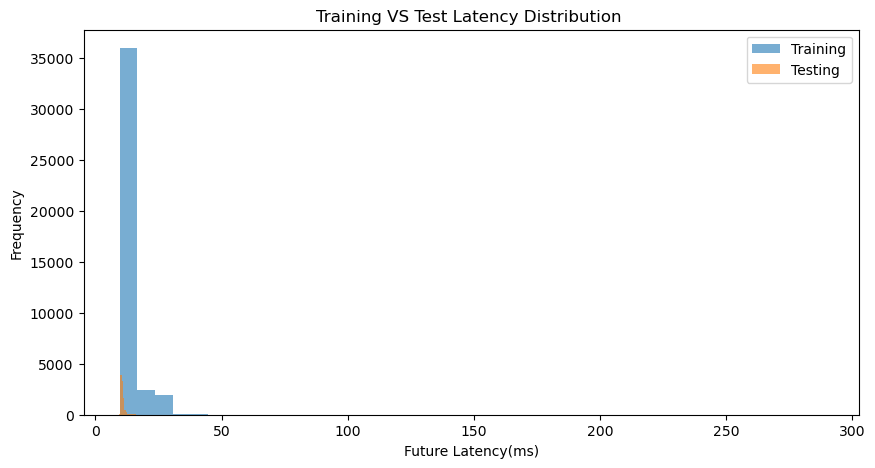

In [131]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.hist(y_train,bins=40, alpha=0.6, label="Training")
plt.hist(y_test,bins=40, alpha=0.6, label="Testing" )
plt.xlabel("Future Latency(ms)")
plt.ylabel("Frequency")
plt.title("Training VS Test Latency Distribution ")
plt.legend()
plt.show()

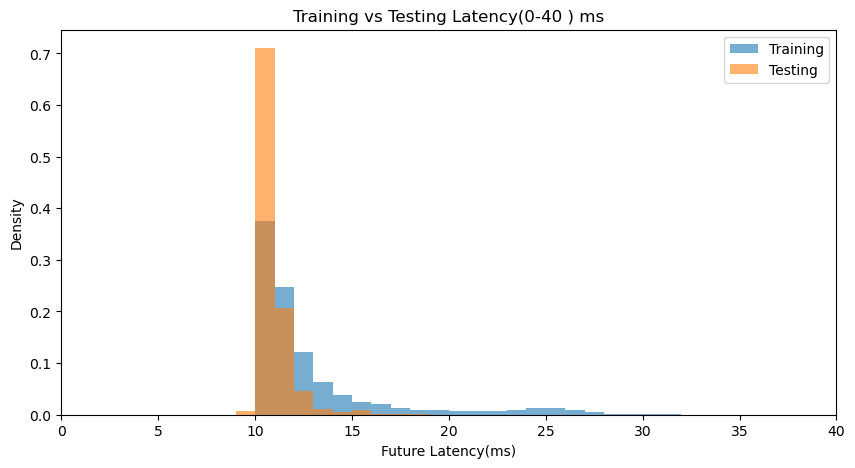

In [132]:
import numpy as np
import matplotlib.pyplot as plt 

bins= np.arange(0,41,1)
plt.figure(figsize=(10,5))
plt.hist(y_train,bins=bins, density=True, alpha =0.6, label='Training')
plt.hist(y_test,bins=bins, density=True,alpha=0.6 , label="Testing" )
plt.xlabel("Future Latency(ms)")
plt.ylabel("Density")
plt.title("Training vs Testing Latency(0-40 ) ms")
plt.xlim(0,40)
plt.legend()
plt.show()

# Conclusion -
The Histogram shows that the training latency values are more widely spread, while the testing latency values are between 10-14ms . This indicates a difference between Training and Testing datasets. The lower variation in the testing-data may partly explain , why the model achieves a negative R2 score . Further analysis of actual vs predicted latency is required to understand the model's performance and to understand the reason behind negative R2 score .

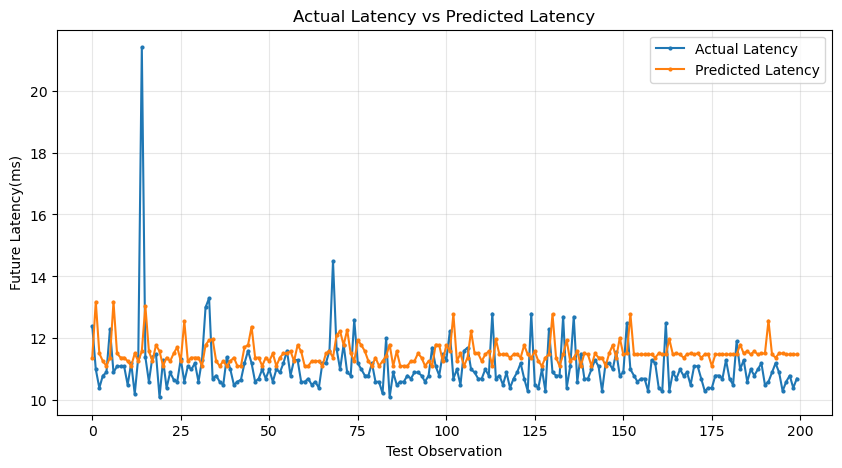

In [133]:
plt.figure(figsize=(10,5))
plt.plot(y_test.iloc[:200].to_numpy(),label="Actual Latency",marker='.',markersize=4)
plt.plot(y_pred[:200],label="Predicted Latency",marker='.', markersize=4)
plt.xlabel("Test Observation")
plt.ylabel("Future Latency(ms)")
plt.title("Actual Latency vs Predicted Latency")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Conclusion-
The actual vs predicted Latency plot shows that the Decision Tree Model generally predicts latency within a narrow range of approximately 10-12 ms . However it does not captures several sudden increase in actual latency. This suggests that the model can estimate typical latency values but struggles to predict short term fluctuations, and latency spikes . Further feature analysis and model tuning is required to improve its predictive performance.

In [134]:
#Check whether timestamp are unique 
df= df.sort_values("timestamp_utc").copy()
#Latency -table 
latency_lookup =df[["timestamp_utc","rtt_avg_ms"]].dropna(subset=["timestamp_utc"]).sort_values("timestamp_utc").copy()
#Finding the closest observation  to the desired pasttime 
def get_past_latency(seconds):
    query= df[["timestamp_utc"]].copy()
    query["desired_time"]= (
        query["timestamp_utc"]-pd.Timedelta(seconds=seconds)
    )
    query = query.sort_values("desired_time")

    matched = pd.merge_asof(
        query,
        latency_lookup ,
        left_on="desired_time",
        right_on= "timestamp_utc",
        direction="nearest",
        tolerance = pd.Timedelta(seconds=5)

    )
    return matched["rtt_avg_ms"].reindex(query.index).sort_index()

In [135]:
df["rtt_avg_30s_ago"]= get_past_latency(30)
df["rtt_avg_60s_ago"]= get_past_latency(60)

In [136]:
# Check the newly created features
df[["timestamp_utc","rtt_avg_ms","rtt_avg_30s_ago","rtt_avg_60s_ago"]].head(15)

,timestamp_utc,rtt_avg_ms,rtt_avg_30s_ago,rtt_avg_60s_ago
0,2026-09-20 16:34:22+00:00,10.500,NaN,NaN
1,2026-09-20 16:35:52+00:00,11.222,NaN,NaN
2,2026-09-20 16:36:22+00:00,10.900,11.222,NaN
3,2026-09-20 16:36:52+00:00,10.500,10.900,11.222
4,2026-09-20 16:37:22+00:00,36.300,10.500,10.900
5,2026-09-20 16:37:52+00:00,10.800,36.300,10.500
6,2026-09-20 16:38:22+00:00,12.400,10.800,36.300
7,2026-09-20 16:38:52+00:00,11.000,12.400,10.800
8,2026-09-20 16:39:22+00:00,11.000,11.000,12.400
9,2026-09-20 16:39:52+00:00,12.400,11.000,11.000


In [137]:
print("Missing 30s lag value : ", df["rtt_avg_30s_ago"].isna().sum())
print("Missing 60s lag value : ", df["rtt_avg_60s_ago"].isna().sum())

Missing 30s lag value :  742
Missing 60s lag value :  805


In [138]:
feature_cols= ["rtt_avg_ms","rtt_median_ms","rtt_max_ms","jitter_ms","packet_loss_pct","gateway_rtt_avg_ms","gateway_jitter_ms","tcp_connect_median_ms","dns_resolve_ms","http_ms","rtt_avg_30s_ago","rtt_avg_60s_ago"]
target_col = "target_rtt_30s"

# Keep the rows where the target exist 
model_df= df.dropna(subset=[target_col]).copy()

# Sort Chronologically
model_df = model_df.sort_values("timestamp_utc").reset_index(drop=True)

# Separate features and Target values 
X= model_df[feature_cols]
y= model_df[target_col]

# Chronological 80:20 split 
split_index = int(len(model_df)*0.80)
X_Train = X.iloc[:split_index]
X_Test= X.iloc[split_index:]
y_train=y.iloc[:split_index]
y_test=y.iloc[split_index:]

In [139]:
print("Training rows : ",len(X_Train))
print("Testing rows :", len(X_Test))
print("Training Missing feature values :",X_Train.isna().sum().sum())
print("Testing Missing feature values :", X_Test.isna().sum().sum())

Training rows :  40486
Testing rows : 10122
Training Missing feature values : 1000
Testing Missing feature values : 181


In [140]:
from sklearn.impute import SimpleImputer 
from sklearn.pipeline import Pipeline 
from sklearn.tree import DecisionTreeRegressor 
from sklearn.metrics import mean_absolute_error,mean_squared_error ,r2_score

# Creating Pipeline 
model_v2=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("regressor",DecisionTreeRegressor(max_depth=8,random_state=42))
])
model_v2.fit(X_Train,y_train)
y_pred_v2 = model_v2.predict(X_Test)

#Evaluate 
mae_v2= mean_absolute_error(y_test,y_pred_v2)
rmse_v2= np.sqrt(mean_squared_error(y_test,y_pred_v2))
r2_v2 = r2_score(y_test, y_pred_v2)

print("Decision Tree V2 Results")
print("MAE :", round(mae_v2,3),"ms")
print("RMSE", round(rmse_v2,3),"ms")
print("R2 Score", round(r2_v2,3))

Decision Tree V2 Results
MAE : 0.71 ms
RMSE 1.035 ms
R2 Score -0.116


In [141]:
# Persistence baseline : current latency predicts future latency 
persistence_pred = X_Test["rtt_avg_ms"]
mae_p= mean_absolute_error(y_test, persistence_pred)
rmse_p=  np.sqrt(mean_squared_error(y_test,persistence_pred))
r2_p= r2_score(y_test,persistence_pred)
print("Decision Tree V2 :")
print("MAE :", round(mae_v2,3))
print("RMSE v2 :" , round(rmse_v2,3))
print("R2_v2 :", round(r2_v2,3))

print("Persistence_baseline :")
print("MAE:", mae_p)
print("RMSE :", rmse_p)
print("R2 Score:", r2_p)

Decision Tree V2 :
MAE : 0.71
RMSE v2 : 1.035
R2_v2 : -0.116
Persistence_baseline :
MAE: 0.5784386484884411
RMSE : 0.9715206250188354
R2 Score: 0.016639395824847747


# Conclusion - Decision Tree V2 
The Decision Tree v2 model was trained using additional lag features to predict future_network latency . However the model achieved an MAE of 0.71 ms and an R2_score of -0.116 , indicating poor predictive performance on the test data.

When compared to the persistence baseline(MAE=0.578ms,R^2=0.017), Decision Tree v2 performed worse. This suggests that adding lag features alone did not improve the model's forecasting capability. 
Therefore further model improvement and evaluation are required before selecting the model for final_network for the final network traffic forecasting dashboard.


In [142]:
import numpy as np 
import pandas as pd
from sklearn.impute import SimpleImputer 
from sklearn.ensemble import RandomForestRegressor 
from sklearn.pipeline import Pipeline 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

# Random Forest Pipeline
rf_model = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("regressor",RandomForestRegressor(n_estimators=200,max_depth=12, random_state=42,n_jobs=-1))
])
# Train 
rf_model.fit(X_Train,y_train)
#Predict 
rf_pred= rf_model.predict(X_Test)

# Evaluate 
rf_mae= mean_absolute_error(y_test,rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test,rf_pred))
rf_r2= r2_score(y_test,rf_pred)

# Decision Tree RMSE(corrected)
dt_rmse= np.sqrt(mean_squared_error(y_test, y_pred_v2))
results= pd.DataFrame({
    "Model": ["Persistence Baseline","Decision Tree V2", "Random Forest V1"],
    "MAE":[mae_p,mae_v2,rf_mae],
    "RMSE" : [rmse_p,dt_rmse,rf_rmse],
    "R2" :[r2_p,r2_v2, rf_r2]
})

print(results.round(3))

                  Model    MAE   RMSE     R2
0  Persistence Baseline  0.578  0.972  0.017
1      Decision Tree V2  0.710  1.035 -0.116
2      Random Forest V1  0.700  0.973  0.015


In [143]:
# check missing values separately in training and testing data 
lag_cols=["rtt_avg_30s_ago","rtt_avg_60s_ago"]
print("Training Data")
print(X_Train[lag_cols].isna().sum())
print("Training rows", len(X_Train))
print("TESTING DATA")
print(X_Test[lag_cols].isna().sum())
print("Testing rows: ", len(X_Test))
# Check time gap between consecutive observations 
time_gaps=( df["timestamp_utc"].sort_values().diff().dt.total_seconds().dropna())

Training Data
rtt_avg_30s_ago    445
rtt_avg_60s_ago    510
dtype: int64
Training rows 40486
TESTING DATA
rtt_avg_30s_ago    84
rtt_avg_60s_ago    92
dtype: int64
Testing rows:  10122


In [144]:
features_to_check =[
    "rtt_avg_ms","rtt_avg_30s_ago","rtt_avg_60s_ago","jitter_ms","packet_loss_pct","target_rtt_30s"
]
df[features_to_check].corr(numeric_only=True).round(3)

,rtt_avg_ms,rtt_avg_30s_ago,rtt_avg_60s_ago,jitter_ms,packet_loss_pct,target_rtt_30s
rtt_avg_ms,1.000,0.736,0.657,0.633,0.058,0.710
rtt_avg_30s_ago,0.736,1.000,0.736,0.431,0.047,0.652
rtt_avg_60s_ago,0.657,0.736,1.000,0.410,0.047,0.610
jitter_ms,0.633,0.431,0.410,1.000,0.170,0.417
packet_loss_pct,0.058,0.047,0.047,0.170,1.000,0.051
target_rtt_30s,0.710,0.652,0.610,0.417,0.051,1.000


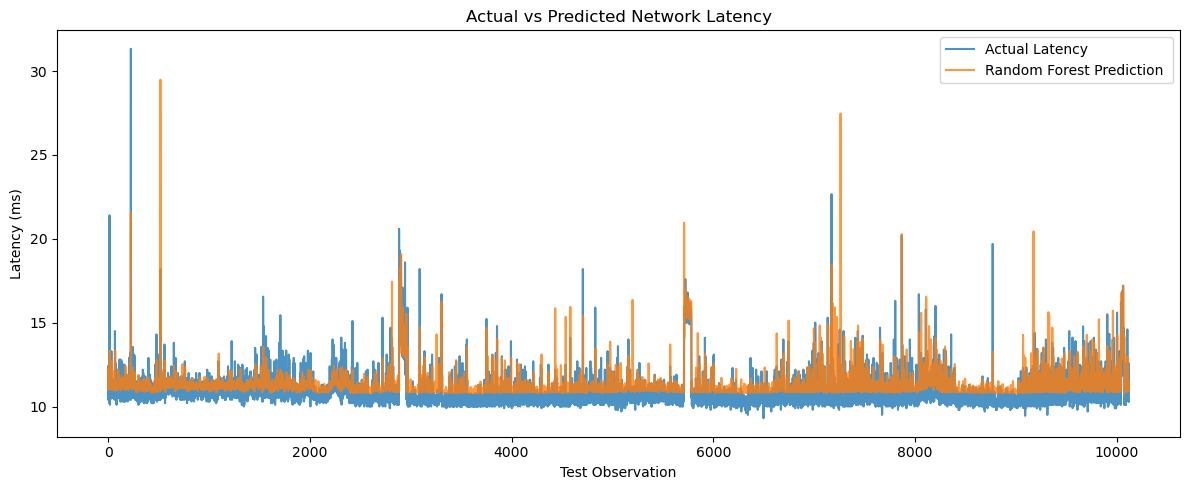

In [145]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(12,5))
plt.plot(
    list(range(len(y_test))),
    y_test.to_numpy(),
    label="Actual Latency",
    alpha =0.8
)
plt.plot(
    list(range(len(rf_pred))),
    rf_pred,
    label= "Random Forest Prediction ",
    alpha =0.8
)
plt.xlabel("Test Observation")
plt.ylabel("Latency (ms)")
plt.title("Actual vs Predicted Network Latency")
plt.legend()
plt.tight_layout()
plt.show()

In [146]:
import numpy as np 
import pandas as pd
from sklearn.metrics import mean_absolute_error

actual = np.asarray(y_test).ravel()
predicted = np.asarray(rf_pred).ravel()

# Comparing prediction variability 
print("Actual Latency Standard Deviation", round(np.std(actual),3))
print("Predicted Latency Standard Deviation",round(np.std(predicted),3))
print("Actual-predicted correlation :",round(np.corrcoef(actual,predicted)[0,1],3))

#Examining the highest 10% of the actual test latencies 
threshold = np.quantile(actual,0.90)
high_latency= actual>=threshold

print("90th percentile Latency Threshold:",round(threshold,3),"ms")
print("High Latency Observations :" ,int((high_latency).sum()))

print("Random Forest MAE on High Latency Observation :")
print(round(mean_absolute_error(actual[high_latency],predicted[high_latency]),3))


Actual Latency Standard Deviation 0.98
Predicted Latency Standard Deviation 0.792
Actual-predicted correlation : 0.535
90th percentile Latency Threshold: 11.7 ms
High Latency Observations : 1039
Random Forest MAE on High Latency Observation :
1.249


In [147]:
df= df.sort_values("timestamp_utc").copy()
df["latency_mean_5"]= df["rtt_avg_ms"].rolling(5).mean()
df["latency_max_5"]= df["rtt_avg_ms"].rolling(5).max()
df["latency_std_5"]= (df["rtt_avg_ms"]).rolling(5).std()
df["latency_change"]= (df["rtt_avg_ms"]-df["rtt_avg_30s_ago"])

In [148]:
df[[
    "rtt_avg_ms",
    "rtt_avg_30s_ago",
    "latency_mean_5",
    "latency_max_5",
    "latency_std_5",
    "latency_change"
]].head(10)

,rtt_avg_ms,rtt_avg_30s_ago,latency_mean_5,latency_max_5,latency_std_5,latency_change
0,10.500,NaN,NaN,NaN,NaN,NaN
1,11.222,NaN,NaN,NaN,NaN,NaN
2,10.900,11.222,NaN,NaN,NaN,-0.322
3,10.500,10.900,NaN,NaN,NaN,-0.400
4,36.300,10.500,15.8844,36.3,11.416682,25.800
5,10.800,36.300,15.9444,36.3,11.382045,-25.500
6,12.400,10.800,16.1800,36.3,11.271513,1.600
7,11.000,12.400,16.2000,36.3,11.259885,-1.400
8,11.000,11.000,16.3000,36.3,11.198661,0.000
9,12.400,11.000,11.5200,12.4,0.807465,1.400


In [149]:
df[[
    "target_rtt_30s",
    "rtt_avg_30s_ago",
    "rtt_avg_60s_ago",
    "latency_mean_5",
    "latency_max_5",
    "latency_std_5",
    "latency_change"
]].isna().sum()

target_rtt_30s     4009
rtt_avg_30s_ago     742
rtt_avg_60s_ago     805
latency_mean_5       38
latency_max_5        38
latency_std_5        38
latency_change      746
dtype: int64

In [150]:
print("Total rows : ",len(df))
print("Target missing rows",df["target_rtt_30s"].isna().sum())
print("First Missing target index:",df.index[df["target_rtt_30s"].isna()][:10].tolist())
print("Last 10 rows :")
display(df[["timestamp_utc","rtt_avg_ms","target_rtt_30s"]].tail(10))

Total rows :  54617
Target missing rows 4009
First Missing target index: [0, 27, 28, 57, 58, 88, 89, 115, 118, 119]
Last 10 rows :


,timestamp_utc,rtt_avg_ms,target_rtt_30s
54607,2026-10-09 19:45:13+00:00,10.5,12.5
54608,2026-10-09 19:45:43+00:00,12.5,10.3
54609,2026-10-09 19:46:13+00:00,10.3,10.5
54610,2026-10-09 19:46:43+00:00,10.5,12.6
54611,2026-10-09 19:47:13+00:00,12.6,10.9
54612,2026-10-09 19:47:43+00:00,10.9,10.4
54613,2026-10-09 19:48:13+00:00,10.4,10.4
54614,2026-10-09 19:48:43+00:00,10.4,12.1
54615,2026-10-09 19:49:13+00:00,12.1,10.3
54616,2026-10-09 19:49:43+00:00,10.3,NaN


In [151]:
missing_indices = df.index[df["target_rtt_30s"].isna()]
df.loc[20:32,["timestamp_utc","rtt_avg_ms","target_rtt_30s"]]

,timestamp_utc,rtt_avg_ms,target_rtt_30s
20,2026-09-20 16:45:22+00:00,10.900,10.800
21,2026-09-20 16:45:52+00:00,10.800,10.800
22,2026-09-20 16:46:22+00:00,10.800,11.200
23,2026-09-20 16:46:52+00:00,11.200,10.800
24,2026-09-20 16:47:22+00:00,10.800,11.100
25,2026-09-20 16:47:52+00:00,11.100,10.800
26,2026-09-20 16:48:22+00:00,10.800,10.500
27,2026-09-20 16:48:52+00:00,10.500,NaN
28,2026-09-20 16:49:42+00:00,12.800,NaN
29,2026-09-20 16:50:22+00:00,11.000,13.444


In [152]:
features = ["rtt_avg_ms","rtt_avg_30s_ago","rtt_avg_60s_ago","jitter_ms","packet_loss_pct","latency_mean_5","latency_max_5","latency_std_5","latency_change"]
target = ["target_rtt_30s"]
model_df= df[features+target].dropna().copy()
print("Original Rows :", len(df))
print("Rows available for modelling",len(model_df))
print("Rows Removed : ", len(df)-len(model_df))

Original Rows : 54617
Rows available for modelling 49532
Rows Removed :  5085


In [153]:
X= model_df[features]
Y= model_df[target]
X.shape

(49532, 9)

In [154]:
X = model_df[features]
y = model_df[target]

split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [155]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model_v2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

In [156]:
rf_model_v2.fit(X_train, y_train)
rf_v2_pred = rf_model_v2.predict(X_test)

mae = mean_absolute_error(y_test, rf_v2_pred)
rmse = np.sqrt(mean_squared_error(y_test, rf_v2_pred))
r2 = r2_score(y_test, rf_v2_pred)

print("Random Forest V2 Results")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

c:\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Random Forest V2 Results
MAE: 0.602
RMSE: 0.855
R2 Score: 0.235


In [157]:
def evaluate_model(true,predicted):
    mae = mean_absolute_error(true,predicted)
    mse = mean_squared_error(true,predicted)
    r2_Score = r2_score(true,predicted)

    return mae,mse,r2_Score

In [158]:
from sklearn.ensemble import AdaBoostRegressor,GradientBoostingRegressor
from xgboost import XGBRegressor 
from sklearn.tree import DecisionTreeRegressor
models={
    'AdaBoostRegressor': AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3),n_estimators=100, learning_rate=0.05,random_state=42),
    'GradientBoostingRegressor': GradientBoostingRegressor( n_estimators=100, learning_rate=0.05,max_depth=3,loss="squared_error",random_state=42),
    'XGB': XGBRegressor(n_estimators=300,learning_rate=0.03,max_depth=3,subsample=0.8,colsample_bytree=0.8,reg_lambda=1,objective="reg:squarederror",random_state=42,n_jobs=-1)
}

for i in range(len(list(models))):
    model= list(models.values())[i]
    model.fit(X_train,y_train.squeeze())

    y_train_pred = model.predict(X_train)
    y_test_pred= model.predict(X_test)

    model_train_mae,model_train_mse,model_train_R2Score= evaluate_model(y_train,y_train_pred)
    model_test_mae,model_test_mse,model_test_R2Score= evaluate_model(y_test,y_test_pred)


    print(list(models.values())[i])
    print("Train Data :")
    print(f"Mean_absolute_error : {model_train_mae}")
    print(f"Mean squared error : {model_train_mse}")
    print(f"R2 score: {model_train_R2Score}" )

    print('----------------------------------------------')

    print("Test Data:")
    print(f"Mean_absolute_error : {model_test_mae}")
    print(f"Mean squared error : {model_test_mse}")
    print(f"R2 score: {model_test_R2Score}" )

    print("================================================")
    print()
    print()



AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=3),
                  learning_rate=0.05, n_estimators=100, random_state=42)
Train Data :
Mean_absolute_error : 1.5015508360797456
Mean squared error : 11.887304660985096
R2 score: 0.6059883362252668
----------------------------------------------
Test Data:
Mean_absolute_error : 1.072953231731186
Mean squared error : 1.4869856091489781
R2 score: -0.5561545531481416


GradientBoostingRegressor(learning_rate=0.05, random_state=42)
Train Data :
Mean_absolute_error : 1.2176110162237064
Mean squared error : 6.988553459810593
R2 score: 0.7683603092031417
----------------------------------------------
Test Data:
Mean_absolute_error : 0.727527746381832
Mean squared error : 0.8333862692669695
R2 score: 0.1278477548998216


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_

In [159]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Persistence Baseline
baseline_pred = X_test["rtt_avg_ms"].to_numpy()

# Evaluation
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print("Persistence Baseline Results")
print("MAE:", baseline_mae)
print("MSE:", baseline_mse)
print("RMSE:", baseline_rmse)
print("R2 Score:", baseline_r2)

Persistence Baseline Results
MAE: 0.5776926415665692
MSE: 0.9311536215807005
RMSE: 0.964963015654331
R2 Score: 0.025532635293974537


           Feature  Importance
5   latency_mean_5    0.437531
0       rtt_avg_ms    0.173628
3        jitter_ms    0.071378
1  rtt_avg_30s_ago    0.069094
8   latency_change    0.062665
2  rtt_avg_60s_ago    0.051344
4  packet_loss_pct    0.048107
6    latency_max_5    0.046468
7    latency_std_5    0.039785


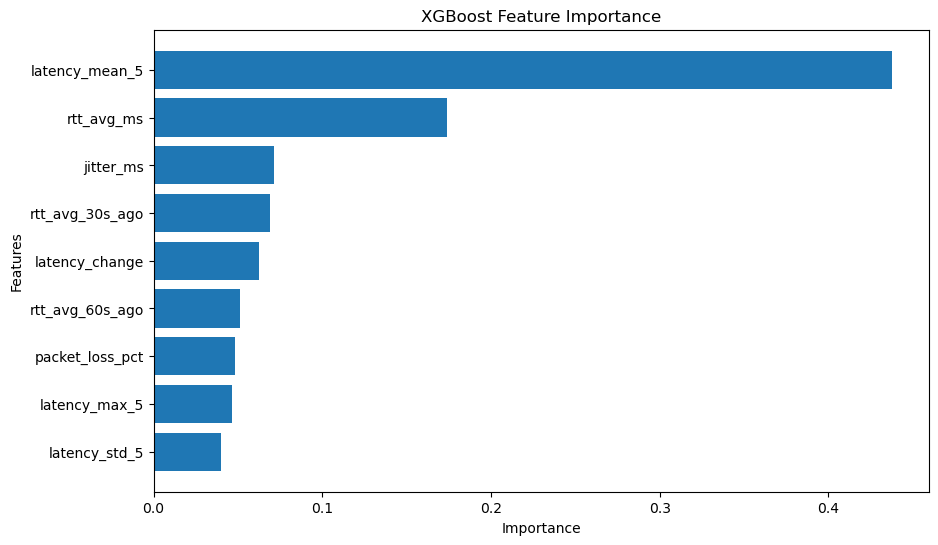

In [160]:
xgb_model = models['XGB']
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()
plt.show()

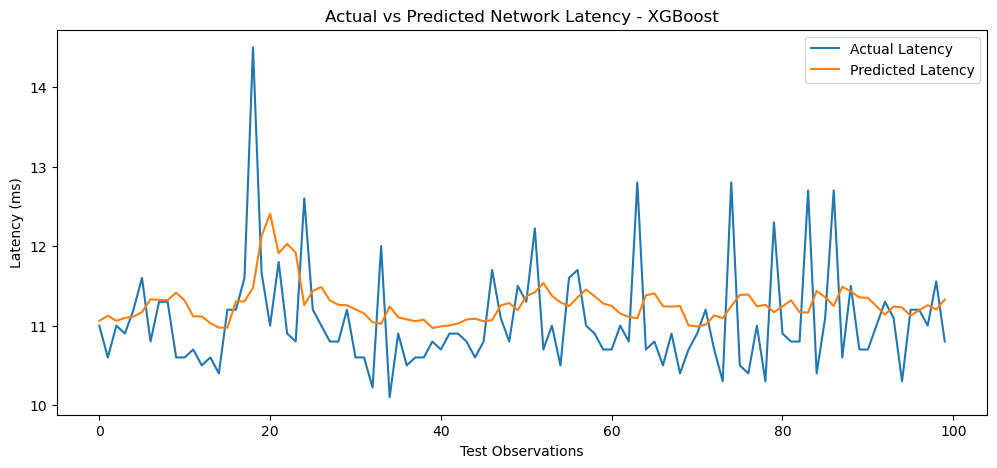

In [161]:
import matplotlib.pyplot as plt
import numpy as np


y_test_pred = xgb_model.predict(X_test)

plt.figure(figsize=(12, 5))

plt.plot(np.array(y_test).ravel()[:100],
         label="Actual Latency")

plt.plot(y_test_pred[:100],
         label="Predicted Latency")

plt.xlabel("Test Observations")
plt.ylabel("Latency (ms)")
plt.title("Actual vs Predicted Network Latency - XGBoost")
plt.legend()
plt.show()

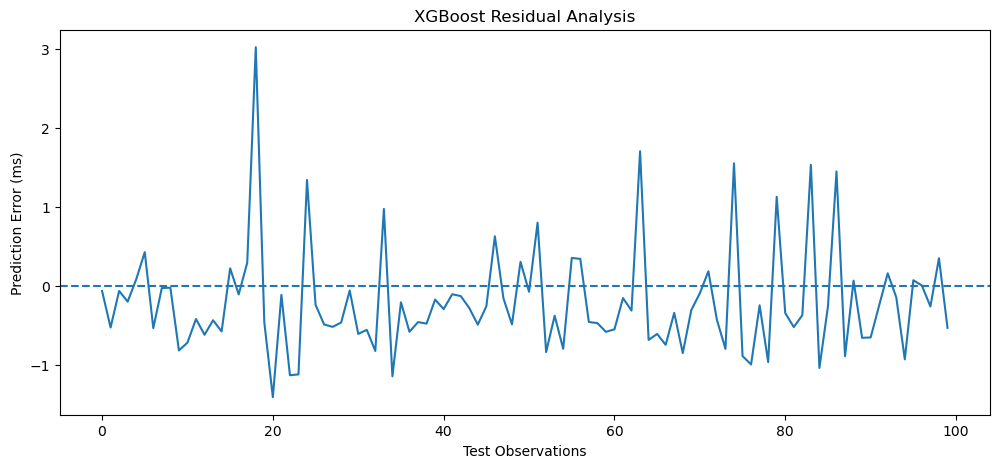

In [162]:
residuals = np.array(y_test).ravel() - y_test_pred

plt.figure(figsize=(12, 5))

plt.plot(residuals[:100])
plt.axhline(y=0, linestyle="--")

plt.xlabel("Test Observations")
plt.ylabel("Prediction Error (ms)")
plt.title("XGBoost Residual Analysis")

plt.show()

In [163]:
print("Mean Residual:", np.mean(residuals))
print("Mean Absolute Error:", np.mean(np.abs(residuals)))
print("Maximum Error:", np.max(np.abs(residuals)))
print("Minimum Residual:", np.min(residuals))
print("Maximum Residual:", np.max(residuals))

Mean Residual: -0.3589492585642422
Mean Absolute Error: 0.645122224026279
Maximum Error: 16.57831555175781
Minimum Residual: -7.758746719360351
Maximum Residual: 16.57831555175781


In [164]:
error_analysis = pd.DataFrame({
    "Actual" : np.array(y_test).ravel(),
    "Predicted": np.array(y_test_pred).ravel(),
    "Residuals" : residuals,
    "Absolute_Error": np.abs(residuals)

}, index=X_test.index)

worst_errors= error_analysis.sort_values(by="Absolute_Error", ascending=False).head(10)
print(worst_errors)

       Actual  Predicted  Residuals  Absolute_Error
43950  31.333  14.754684  16.578316       16.578316
43949  27.200  11.773300  15.426700       15.426700
51438  22.667  11.391296  11.275704       11.275704
46821  20.600  10.970744   9.629256        9.629256
52187  20.200  11.150122   9.049878        9.049878
53161  19.700  10.970744   8.729256        8.729256
44271  10.900  18.658747  -7.758747        7.758747
44270  10.400  17.914387  -7.514387        7.514387
48787  18.200  10.974451   7.225549        7.225549
47040  18.200  11.242113   6.957887        6.957887


In [165]:
worst_cases = pd.concat([X_test,error_analysis],axis=1)

worst_cases= worst_cases.sort_values(by="Absolute_Error",ascending=False).head(10)
print(worst_cases)
fd = pd.DataFrame(worst_cases)
fd

       rtt_avg_ms  rtt_avg_30s_ago  rtt_avg_60s_ago  jitter_ms  \
43950        27.2           11.100             11.4      5.778   
43949        11.1           11.400             12.6      0.778   
51438        10.3           11.111             11.4      0.444   
46821        10.8           10.100             10.3      0.667   
52187        10.3           11.667             10.7      0.556   
53161        10.1           10.600             10.6      0.889   
44271        10.4           18.200             34.2      0.667   
44270        18.2           34.200             31.0     11.778   
48787        10.4           10.700             10.5      0.778   
47040        11.0           11.200             10.9      1.222   

       packet_loss_pct  latency_mean_5  latency_max_5  latency_std_5  \
43950              0.0         14.6800         27.200       7.026165   
43949              0.0         11.8800         13.200       0.962808   
51438              0.0         11.5622         12.700    

,rtt_avg_ms,rtt_avg_30s_ago,rtt_avg_60s_ago,jitter_ms,packet_loss_pct,latency_mean_5,latency_max_5,latency_std_5,latency_change,Actual,Predicted,Residuals,Absolute_Error
43950,27.2,11.100,11.4,5.778,0.0,14.6800,27.200,7.026165,16.100,31.333,14.754684,16.578316,16.578316
43949,11.1,11.400,12.6,0.778,0.0,11.8800,13.200,0.962808,-0.300,27.200,11.773300,15.426700,15.426700
51438,10.3,11.111,11.4,0.444,0.0,11.5622,12.700,0.956815,-0.811,22.667,11.391296,11.275704,11.275704
46821,10.8,10.100,10.3,0.667,0.0,10.4200,10.800,0.258844,0.700,20.600,10.970744,9.629256,9.629256
52187,10.3,11.667,10.7,0.556,0.0,10.7734,11.667,0.521572,-1.367,20.200,11.150122,9.049878,9.049878
53161,10.1,10.600,10.6,0.889,0.0,10.3000,10.600,0.282843,-0.500,19.700,10.970744,8.729256,8.729256
44271,10.4,18.200,34.2,0.667,0.0,21.2400,34.200,10.817948,-7.800,10.900,18.658747,-7.758747,7.758747
44270,18.2,34.200,31.0,11.778,0.0,21.3600,34.200,10.669958,-16.000,10.400,17.914387,-7.514387,7.514387
48787,10.4,10.700,10.5,0.778,0.0,10.5600,10.900,0.240832,-0.300,18.200,10.974451,7.225549,7.225549
47040,11.0,11.200,10.9,1.222,0.0,11.0800,11.800,0.476445,-0.200,18.200,11.242113,6.957887,6.957887


In [166]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [167]:
baseline_pred = X_test["rtt_avg_ms"].to_numpy()

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("Persistence Baseline")
print("MAE:", round(baseline_mae, 3))
print("RMSE:", round(baseline_rmse, 3))
print("R2:", round(baseline_r2, 3))

Persistence Baseline
MAE: 0.578
RMSE: 0.965
R2: 0.026


In [168]:
threshold = 11.7

y_true = np.asarray(y_test).reshape(-1)
predictions = np.asarray(rf_v2_pred).reshape(-1)

print("Actual shape:", y_true.shape)
print("Prediction shape:", predictions.shape)

high_latency_mask = y_true >= threshold

high_latency_mae = mean_absolute_error(
    y_true[high_latency_mask],
    predictions[high_latency_mask]
)

print("High latency observations:", high_latency_mask.sum())
print("RF V2 High Latency MAE:", round(high_latency_mae, 3), "ms")

Actual shape: (9907,)
Prediction shape: (9907,)
High latency observations: 1016
RF V2 High Latency MAE: 1.319 ms


# Actual vs Predicted Latency Graph 


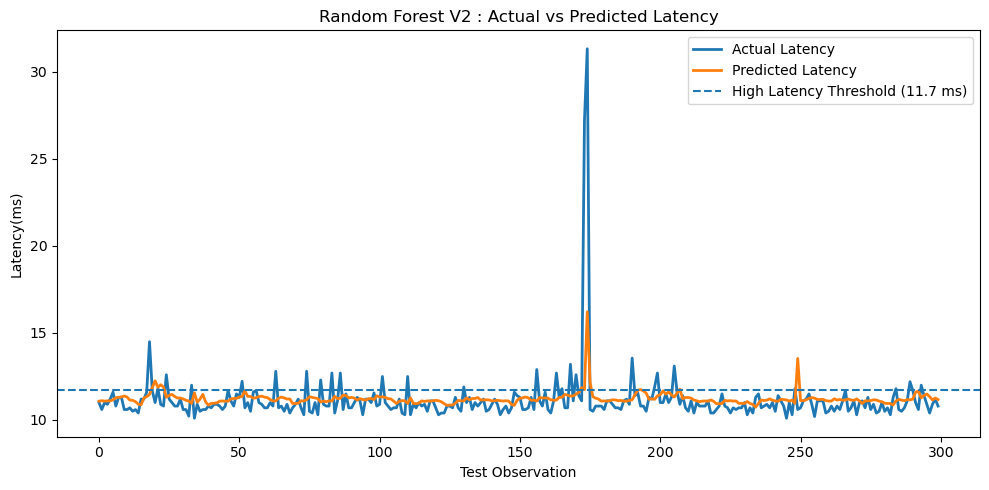

In [169]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.plot(
    y_true[:300],
    label="Actual Latency",
    linewidth=2
)
plt.plot(
    predictions[:300],
    label="Predicted Latency",
    linewidth =2
)
plt.axhline(
    y= threshold,
    linestyle="--",
    label = "High Latency Threshold (11.7 ms)"
)
plt.xlabel("Test Observation")
plt.ylabel("Latency(ms)")
plt.title("Random Forest V2 : Actual vs Predicted Latency")
plt.legend()
plt.tight_layout()
plt.show()

# High Latency Risk Indicator


In [170]:
threshold=11.7
risk_level= np.where(rf_v2_pred>=threshold, "High Latency Risk","Normal")
print("Normal Predictions :", np.sum(risk_level=="Normal"))
print("High Latency Risk Prediction :", np.sum(risk_level=="High Latency Risk"))


Normal Predictions : 9376
High Latency Risk Prediction : 531


In [171]:
from sklearn.metrics import confusion_matrix, classification_report

threshold = 11.7
actual_high = (y_true >= threshold).astype(int)
predicted_high = (rf_v2_pred >= threshold).astype(int)

print(confusion_matrix(actual_high, predicted_high))
print(classification_report(
    actual_high, predicted_high,
    target_names=["Normal", "High Latency"],
    zero_division=0
))

[[8610  281]
 [ 766  250]]
              precision    recall  f1-score   support

      Normal       0.92      0.97      0.94      8891
High Latency       0.47      0.25      0.32      1016

    accuracy                           0.89      9907
   macro avg       0.69      0.61      0.63      9907
weighted avg       0.87      0.89      0.88      9907



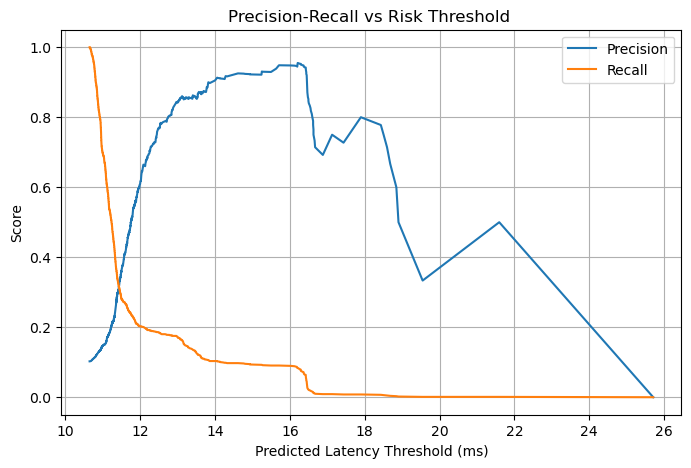

In [172]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

actual_high= (y_true>=11.7).astype(int)
precision,recall,thresholds= precision_recall_curve(actual_high, rf_v2_pred)
plt.figure(figsize=(8,5))
plt.plot(thresholds,precision[:-1], label="Precision")
plt.plot(thresholds,recall[:-1], label="Recall")
plt.xlabel("Predicted Latency Threshold (ms)")
plt.ylabel("Score")
plt.title("Precision-Recall vs Risk Threshold ")
plt.legend();
plt.grid(True)
plt.show()

In [173]:
from sklearn.metrics import precision_recall_curve
import numpy as np 

actual_high = (y_true>=11.7).astype(int)
precision,recall,thresholds= precision_recall_curve(actual_high, rf_v2_pred)

f1_scores= 2* precision[:-1]*recall[:-1]/(precision[:-1]+recall[:-1] + 1e-10)

best_idx = np.argmax(f1_scores)
best_threshold =  thresholds[best_idx]

print("Best threshold : ", round(best_threshold,3),"ms")
print("Precision : ", round(precision[best_idx],3))
print("Recall :", round(recall[best_idx],3))
print("F1_Score", round (f1_scores[best_idx],3))


Best threshold :  11.621 ms
Precision :  0.427
Recall : 0.267
F1_Score 0.328


In [174]:
from sklearn.metrics import confusion_matrix, classification_report 
best_threshold= 11.621
actual_high = (y_true>=11.7).astype(int)
predicted_high_tuned= (rf_v2_pred>=best_threshold).astype(int)
print("Confusion_matrix")
print(confusion_matrix(actual_high,predicted_high_tuned))


Confusion_matrix
[[8529  362]
 [ 746  270]]


In [175]:
print(classification_report(
    actual_high,
    predicted_high_tuned,
    target_names=["Normal", "High Latency"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       0.92      0.96      0.94      8891
High Latency       0.43      0.27      0.33      1016

    accuracy                           0.89      9907
   macro avg       0.67      0.61      0.63      9907
weighted avg       0.87      0.89      0.88      9907



In [176]:
print("Random Forest V2 Results")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))


print("Persistence Baseline")
print("MAE:", round(baseline_mae, 3))
print("RMSE:", round(baseline_rmse, 3))
print("R2:", round(baseline_r2, 3))

Random Forest V2 Results
MAE: 0.602
RMSE: 0.855
R2 Score: 0.235
Persistence Baseline
MAE: 0.578
RMSE: 0.965
R2: 0.026


# Conclusion:-
 The random_v2 model outperformed the baseline model , however in case of mae , the baseline performed good

In [177]:
df.columns
pd=df.to_csv("final.csv")